<a href="https://colab.research.google.com/github/AkiraKirito/Cell-Tracking-Challenge/blob/main/CellTracking_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
# --- Colab setup -----------------------------------------------------------
import os, sys
!nvidia-smi -L                                    # should list a GPU

# Code: main + the three feature branches (none are merged yet)
%cd /content
!git clone -q https://github.com/wyl2003/Cell-Tracking-Challenge.git ctc
%cd /content/ctc
!git fetch -q https://github.com/wyl2003/Cell-Tracking-Challenge.git feature/segmentation-improvement:seg
!git fetch -q https://github.com/tuzzzzi/Cell-Tracking-Challenge.git feature/baseline-tracking:base
!git checkout -q seg -- src                       # Shu: multiscale, temporal, border filter (adds files only)
!git checkout -q base -- src/baseline_tracking    # ZIHAO: optimized linker
sys.path.insert(0, "/content/ctc")

# Packages, same versions as the team's runs
!pip install -q cellpose==4.2.1.1 trackastra==0.5.6 motile ilpy py-ctcmetrics==1.3.3 jupytext

# Data (CTC training sets)
!mkdir -p data
!wget -q -nc -P data http://data.celltrackingchallenge.net/training-datasets/Fluo-N2DH-GOWT1.zip
!wget -q -nc -P data http://data.celltrackingchallenge.net/training-datasets/Fluo-N2DL-HeLa.zip
!cd data && unzip -q -n Fluo-N2DH-GOWT1.zip && unzip -q -n Fluo-N2DL-HeLa.zip
!ls data

GPU 0: Tesla T4 (UUID: GPU-8ced276a-624a-f9e8-efa6-8484dd15620a)
/content
fatal: destination path 'ctc' already exists and is not an empty directory.
/content/ctc
Fluo-N2DH-GOWT1  Fluo-N2DH-GOWT1.zip  Fluo-N2DL-HeLa  Fluo-N2DL-HeLa.zip


In [29]:
import motile, ilpy, trackastra, cellpose, torch
print("cuda:", torch.cuda.is_available())

cuda: True


In [30]:
%cd /content/ctc
import sys; sys.path.insert(0, "/content/ctc")

/content/ctc


# Cell Segmentation and Tracking on the Cell Tracking Challenge
**COMP9444 26T3 · Project 15 · Team: _TODO team name_**

| Member | zID | Main contribution (sections) |
|---|---|---|
| _TODO_ | z_______ | Data & EDA (§2–3) |
| _TODO_ | z_______ | Segmentation (§4.2, M1) |
| _TODO_ | z_______ | Tracking & divisions (§4.3) |
| _TODO_ | z_______ | Evaluation & error analysis (§5–6) |
| _TODO_ | z_______ | Report, slides, notebook integration |

**How to run.** Run top to bottom from the repository root. The S-rows (multi-scale, temporal, border
filter) need the modules from the `feature/segmentation-improvement` branch. Without them those rows
are skipped with a warning. Trackastra rows need `trackastra` (ILP rows also need `motile` + `ilpy`).
The fine-tuned rows need ZIHAO LI's checkpoint folder at `models/trackastra_gowt1_finetuned/`, or set
`TRACKASTRA_FINETUNED`. §5.10 runs only if `data/Fluo-N2DL-HeLa/` exists. The `L*` rows (optimized
IoU linker) need `src/baseline_tracking/` from ZIHAO LI's `feature/baseline-tracking` branch.

**Where the code comes from** (merge these into `main` before the final run):

| branch | author | adds |
|---|---|---|
| `main` | Wang Yile (wyl2003) | scaffold, IoU linker, Cellpose and Trackastra baselines |
| `feature/segmentation-improvement` | Shu Lian | multi-scale and temporal recovery, border filter |
| `feature/baseline-tracking` | ZIHAO LI (tuzzzzi) | optimized IoU-Hungarian linker and its ablations |
| `feature/trackastra-tracking` | ZIHAO LI (tuzzzzi) | Trackastra fine-tuning, Greedy vs ILP, HeLa cross-dataset | Expensive steps (segmentation,
evaluation) are cached under `runs/` and `results/`, so a re-run only recomputes what changed.
Set the flags in §0 to control what gets recomputed. The data is **not** in the repository
(CTC licence); download it into `data/` as described in §2.

## 0. Setup and configuration

In [31]:
from __future__ import annotations

import os
import shutil
import subprocess
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile
from scipy import ndimage
from scipy.spatial import cKDTree

from src import ctc_io
from src.diagnostics import WEIGHTS, decompose
from src.error_analysis import analyse, summarise
from src.track import track_sequence
from src.run_track import save_result

# ---- paths ---------------------------------------------------------------------------
DATA_ROOT = Path(os.environ.get("CTC_DATA_ROOT", "data"))
DATASET = "Fluo-N2DH-GOWT1"
SEQS = ["01", "02"]
DS = DATA_ROOT / DATASET
HELA_DS = DATA_ROOT / "Fluo-N2DL-HeLa"   # cross-dataset evaluation (§5.10); skipped if absent
RUNS = Path("runs/nb")          # cached masks and result folders
RESULTS = Path("results")       # metric tables (CSV)
FIGS = Path("figs")             # figures for the report
for p in (RUNS, RESULTS, FIGS):
    p.mkdir(parents=True, exist_ok=True)

# ---- what to recompute ---------------------------------------------------------------
RECOMPUTE_SEGMENTATION = False  # True: rerun segmenters even if cached masks exist
RECOMPUTE_TRACKING = False      # True: rerun linkers even if a <seq>_RES folder exists
RECOMPUTE_METRICS = False       # True: re-score every experiment

SEED = 0
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False,
                     "axes.spines.right": False})

assert DS.is_dir(), f"dataset not found at {DS.resolve()} - see section 2"
print("dataset:", DS.resolve())

dataset: /content/ctc/data/Fluo-N2DH-GOWT1


## 1. Introduction and motivation

_TODO (≈1 paragraph + 2–3 citations)._ Why track cells: lineage reconstruction, cell-cycle
timing, drug screening, cancer cell migration. Why it is hard: low contrast, cells entering and
leaving the field of view, and divisions that turn one track into two.

**Task.** Given a time-lapse microscopy sequence, output (1) an instance segmentation of every
nucleus in every frame and (2) a lineage table `L B E P` (track label, first frame, last frame,
parent). The CTC scores these with three official measures:

* **SEG**: mean Jaccard of matched instances (on the frames with gold segmentation only)
* **DET**: detection accuracy, a normalised graph-edit cost on the nodes
* **TRA**: `1 − min(AOGM, AOGM₀)/AOGM₀`, where
  `AOGM = 5·NS + 10·FN + 1·FP + 1·ED + 1.5·EA + 1·EC`

A missed cell (FN, weight 10) costs ten times a spurious one (FP, weight 1), so the metric is
**recall-dominated**. This shapes every threshold choice below.

**Research question.** _TODO: state it in one sentence, e.g. "Where does the remaining error of a
strong zero-shot segmenter + simple linker come from, and which targeted fixes recover it?"_

## 2. Data sources

* **Dataset:** `Fluo-N2DH-GOWT1` (GFP-tagged mouse embryonic stem cell nuclei, 2D widefield),
  Cell Tracking Challenge, <https://celltrackingchallenge.net/2d-datasets/>.
* **Licence:** CTC data may be used for research but **not redistributed**, so it is not committed
  here (`data/` is in `.gitignore`).
* **Download:** the training archive from the page above, unzipped into
  `data/Fluo-N2DH-GOWT1/{01,01_GT,02,02_GT}`. The host `data.celltrackingchallenge.net` can time out
  off-campus; use the UNSW network or VPN.
* **Annotations:** `GT/TRA` = gold tracking markers for *every* frame plus `man_track.txt`;
  `GT/SEG` = gold full segmentations for a *subset* of frames; `ST` = silver (machine-generated)
  segmentations for all frames. **Silver truth is used for training only, never for scoring.**
* **Cross-dataset test set:** `Fluo-N2DL-HeLa` (H2B-GFP HeLa nuclei), from the same page, unzipped into
  `data/Fluo-N2DL-HeLa/`. Both labelled sequences are used for scoring only (§5.10).
* **Split:** leave-one-sequence-out. Tune on `01` and report on `02`, then swap. The CTC challenge
  sequences have no public GT and are not used.

In [32]:
def tif_files(d: Path) -> list[Path]:
    return sorted(d.glob("*.tif")) if d.is_dir() else []


rows = []
for seq in SEQS:
    frames = tif_files(DS / seq)
    img0 = tifffile.imread(frames[0])
    tra = tif_files(DS / f"{seq}_GT" / "TRA")
    seg = tif_files(DS / f"{seq}_GT" / "SEG")
    st = tif_files(DS / f"{seq}_ST" / "SEG")
    table = ctc_io.read_track_table(DS / f"{seq}_GT" / "TRA" / "man_track.txt")
    rows.append({
        "sequence": seq, "frames": len(frames), "shape": "×".join(map(str, img0.shape)),
        "dtype": str(img0.dtype), "GT TRA frames": len(tra), "GT SEG frames": len(seg),
        "ST SEG frames": len(st), "GT tracks": len(table),
        "GT divisions": len({int(p) for p in table[:, 3] if p > 0}),
    })
inventory = pd.DataFrame(rows).set_index("sequence")
inventory

,frames,shape,dtype,GT TRA frames,GT SEG frames,ST SEG frames,GT tracks,GT divisions
sequence,,,,,,,,
01,92,1024×1024,uint8,92,30,92,28,3
02,92,1024×1024,uint8,92,20,92,58,9


*Table 1. Dataset inventory. A "division" is one mother with `P > 0` children. The number of
tracks with a parent is twice this.*

## 3. Exploratory data analysis

EDA is computed from the **gold TRA markers** (available for every frame) and the raw images.
All per-object statistics are vectorised with `scipy.ndimage`, so the whole section runs in seconds.

In [33]:
def load_seq(seq: str):
    imgs = {ctc_io.frame_index(p): tifffile.imread(p) for p in tif_files(DS / seq)}
    tra = {f: ctc_io.read_mask(p) for f, p in ctc_io.list_masks(DS / f"{seq}_GT" / "TRA").items()}
    seg_dir = DS / f"{seq}_GT" / "SEG"
    seg = {f: ctc_io.read_mask(p) for f, p in ctc_io.list_masks(seg_dir).items()} if seg_dir.is_dir() else {}
    table = ctc_io.read_track_table(DS / f"{seq}_GT" / "TRA" / "man_track.txt")
    return imgs, tra, seg, table


def object_table(imgs, masks, seq) -> pd.DataFrame:
    """One row per (frame, label): area, centroid, mean intensity, border distance, NN distance."""
    out = []
    for f, m in masks.items():
        labels = np.unique(m)
        labels = labels[labels > 0]
        if labels.size == 0:
            continue
        img = imgs[f].astype(np.float64)
        area = ndimage.sum_labels(np.ones_like(m), m, labels)
        com = np.array(ndimage.center_of_mass(np.ones_like(m), m, labels))
        inten = ndimage.mean(img, m, labels)
        h, w = m.shape
        objs = ndimage.find_objects(m)
        border = [min(objs[l - 1][0].start, objs[l - 1][1].start,
                      h - objs[l - 1][0].stop, w - objs[l - 1][1].stop) for l in labels]
        nn = cKDTree(com).query(com, k=2)[0][:, 1] if len(labels) > 1 else [np.nan]
        for i, l in enumerate(labels):
            out.append(dict(seq=seq, frame=f, label=int(l), area=area[i], cy=com[i, 0], cx=com[i, 1],
                            intensity=inten[i], border=border[i], nn_dist=nn[i]))
    return pd.DataFrame(out)


def touching_fraction(m: np.ndarray) -> float:
    """Fraction of objects that share a 4-connected boundary with another object."""
    touching = set()
    for a, b in ((m[1:, :], m[:-1, :]), (m[:, 1:], m[:, :-1])):
        sel = (a != b) & (a > 0) & (b > 0)
        touching |= set(np.unique(a[sel])) | set(np.unique(b[sel]))
    n = len(np.unique(m)) - 1
    return len(touching) / n if n else 0.0


DATA = {seq: load_seq(seq) for seq in SEQS}
OBJ = pd.concat([object_table(DATA[s][0], DATA[s][1], s) for s in SEQS], ignore_index=True)
OBJ.groupby("seq")[["area", "intensity", "nn_dist"]].describe().T.round(1)

seq                  01      02
area      count  2058.0  2517.0
          mean   1805.7  1665.3
          std     665.8   760.7
          min      45.0    25.0
          25%    1420.2  1220.0
          50%    1649.0  1556.0
          75%    1895.5  1941.0
          max    4522.0  4659.0
intensity count  2058.0  2517.0
          mean     35.0    14.0
          std      25.2     9.9
          min       2.7     1.6
          25%      16.4     7.7
          50%      28.5    10.2
          75%      46.4    19.0
          max     119.5    62.8
nn_dist   count  2058.0  2517.0
          mean    123.1   115.9
          std      61.2    28.0
          min      32.4    40.2
          25%      92.2    96.5
          50%     105.8   116.6
          75%     124.4   130.2
          max     306.2   199.3

### 3.1 What the data looks like

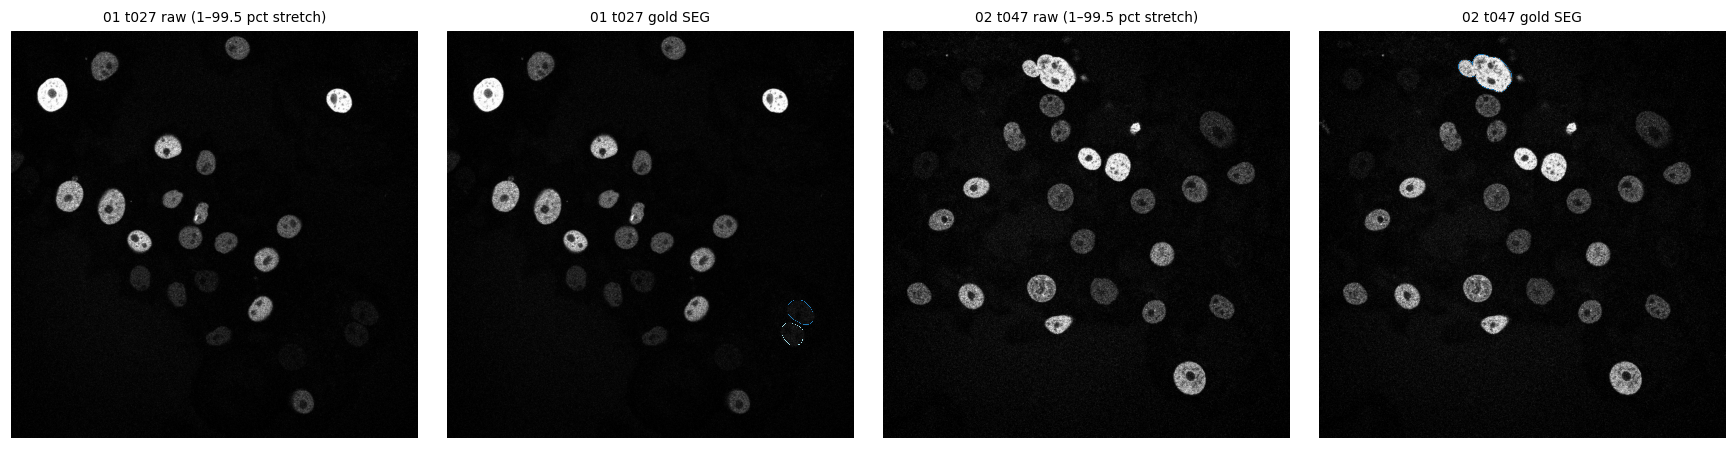

In [34]:
def show_overlay(ax, img, mask, title):
    lo, hi = np.percentile(img, [1, 99.5])
    ax.imshow(np.clip((img - lo) / max(hi - lo, 1e-6), 0, 1), cmap="gray")
    edge = mask != ndimage.grey_erosion(mask, size=3)
    ax.imshow(np.ma.masked_where(~(edge & (mask > 0)), mask), cmap="tab20", interpolation="nearest")
    ax.set_title(title, fontsize=9)
    ax.axis("off")


fig, axes = plt.subplots(1, 2 * len(SEQS), figsize=(4 * 2 * len(SEQS), 4))
for i, seq in enumerate(SEQS):
    imgs, tra, seg, _ = DATA[seq]
    f_mid = sorted(seg)[len(seg) // 2] if seg else sorted(tra)[0]
    raw = imgs[f_mid].astype(float)
    lo, hi = np.percentile(raw, [1, 99.5])
    axes[2 * i].imshow(np.clip((raw - lo) / max(hi - lo, 1e-6), 0, 1), cmap="gray")
    axes[2 * i].set_title(f"{seq} t{f_mid:03d} raw (1–99.5 pct stretch)", fontsize=9)
    axes[2 * i].axis("off")
    show_overlay(axes[2 * i + 1], raw, seg.get(f_mid, tra[f_mid]),
                 f"{seq} t{f_mid:03d} gold {'SEG' if seg else 'TRA'}")
plt.tight_layout()
plt.savefig(FIGS / "nb_eda_frames.png", bbox_inches="tight")
plt.show()

*Figure 1. A representative frame per sequence, raw and with gold outlines. The contrast stretch
is per image. Some nuclei are near-invisible at a linear stretch (see §3.2).*

### 3.2 Objects: count, size, brightness, spacing

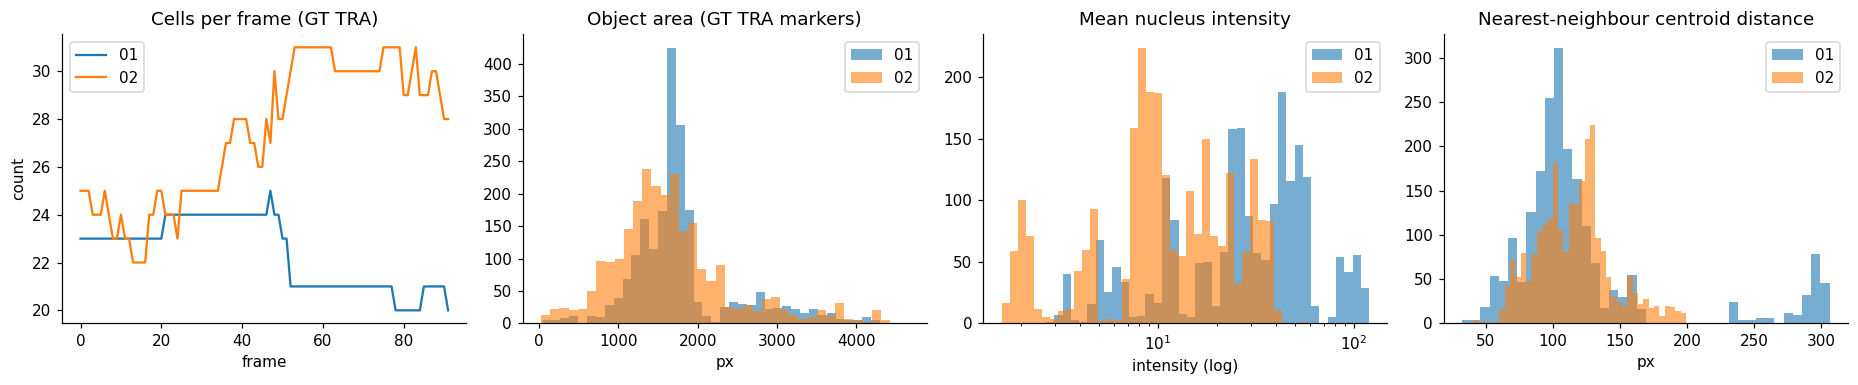

,cells_per_frame,median_area,intensity_p5,intensity_p95,median_nn_dist,near_border_pct,brightness_range_p95/p5,touching_pct
seq,,,,,,,,
01,23.0,1649.0,5.10,97.10,105.77,2.92,19.04,0.09
02,28.0,1556.0,2.01,34.27,116.58,0.16,17.05,0.00


In [35]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for seq, g in OBJ.groupby("seq"):
    per_frame = g.groupby("frame").size()
    axes[0].plot(per_frame.index, per_frame.values, label=seq)
    axes[1].hist(g["area"], bins=40, alpha=0.6, label=seq)
    axes[2].hist(g["intensity"], bins=np.logspace(np.log10(max(g["intensity"].min(), 0.1)),
                                                   np.log10(g["intensity"].max()), 40), alpha=0.6, label=seq)
    axes[3].hist(g["nn_dist"].dropna(), bins=40, alpha=0.6, label=seq)
axes[0].set(title="Cells per frame (GT TRA)", xlabel="frame", ylabel="count")
axes[1].set(title="Object area (GT TRA markers)", xlabel="px")
axes[2].set(title="Mean nucleus intensity", xlabel="intensity (log)", xscale="log")
axes[2].xaxis.set_minor_formatter(plt.NullFormatter())
axes[3].set(title="Nearest-neighbour centroid distance", xlabel="px")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig(FIGS / "nb_eda_objects.png", bbox_inches="tight")
plt.show()

summary = OBJ.groupby("seq").agg(
    cells_per_frame=("frame", lambda s: s.value_counts().median()),
    median_area=("area", "median"),
    intensity_p5=("intensity", lambda s: np.percentile(s, 5)),
    intensity_p95=("intensity", lambda s: np.percentile(s, 95)),
    median_nn_dist=("nn_dist", "median"),
    near_border_pct=("border", lambda s: 100 * (s <= 8).mean()),
)
summary["brightness_range_p95/p5"] = summary.intensity_p95 / summary.intensity_p5
summary["touching_pct"] = [100 * np.mean([touching_fraction(m) for m in DATA[s][1].values()]) for s in SEQS]
summary.round(2)

*Figure 2 / Table 2. Object statistics from the gold markers.* **Key observations to write up:**
_TODO, update with the printed numbers._ For example: the brightness spread between the
dimmest and brightest nuclei (p95/p5), which predicts where a zero-shot model will miss cells;
whether nuclei touch (if they almost never do, merges (NS) will be rare and splitting is not the
problem); and the fraction of objects within 8 px of the border.

#### Gold SEG vs gold TRA annotations disagree on size

In [36]:
rows = []
for seq in SEQS:
    _, tra, seg, _ = DATA[seq]
    for f, sm in seg.items():
        tm = tra[f]
        for l in np.unique(sm)[1:]:
            overlap = tm[sm == l]
            overlap = overlap[overlap > 0]
            if overlap.size:
                t = np.bincount(overlap).argmax()
                rows.append(dict(seq=seq, seg_area=(sm == l).sum(), tra_area=(tm == t).sum()))
sz = pd.DataFrame(rows)
if len(sz):
    sz["ratio"] = sz.seg_area / sz.tra_area
    display(sz.groupby("seq")[["seg_area", "tra_area", "ratio"]].median().round(2))

,seg_area,tra_area,ratio
seq,,,
01,2847.0,1649.0,1.73
02,3095.0,1649.0,1.89


*Table 3. Median per-object area in the two gold annotation sets.* `TRA` markers are not full
segmentations, so any analysis of object size must use `SEG`. This also means the oracle row in
§5 (tracking the TRA markers) is an upper bound for **linking**, not for SEG.

### 3.3 Motion and lineage

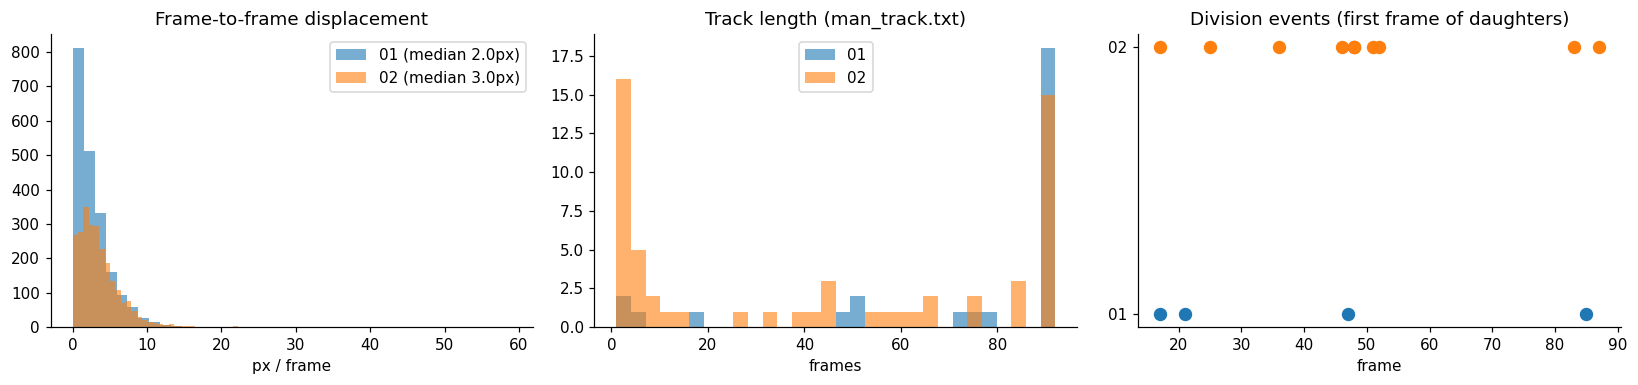

01: median step 2.0px = 0.04 nucleus diameters; p99 11.6px
02: median step 3.0px = 0.07 nucleus diameters; p99 13.9px


In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for seq in SEQS:
    g = OBJ[OBJ.seq == seq].sort_values(["label", "frame"])
    d = g.groupby("label")[["cy", "cx", "frame"]].diff()
    step = np.hypot(d.cy, d.cx)[d.frame == 1]
    axes[0].hist(step, bins=40, alpha=0.6, label=f"{seq} (median {step.median():.1f}px)")
    table = DATA[seq][3]
    axes[1].hist(table[:, 2] - table[:, 1] + 1, bins=30, alpha=0.6, label=seq)
    births = table[table[:, 3] > 0]
    div_frames = sorted({(int(p), int(b)) for _, b, _, p in births})
    axes[2].scatter([b for _, b in div_frames], [seq] * len(div_frames), s=60, label=seq)
axes[0].set(title="Frame-to-frame displacement", xlabel="px / frame")
axes[1].set(title="Track length (man_track.txt)", xlabel="frames")
axes[2].set(title="Division events (first frame of daughters)", xlabel="frame")
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.savefig(FIGS / "nb_eda_motion.png", bbox_inches="tight")
plt.show()

# median displacement relative to nucleus size -> how much IoU-based linking can rely on overlap
for seq in SEQS:
    g = OBJ[OBJ.seq == seq].sort_values(["label", "frame"])
    d = g.groupby("label")[["cy", "cx", "frame"]].diff()
    step = np.hypot(d.cy, d.cx)[d.frame == 1]
    diam = 2 * np.sqrt(g.area.median() / np.pi)
    print(f"{seq}: median step {step.median():.1f}px = {step.median() / diam:.2f} nucleus diameters; "
          f"p99 {np.percentile(step, 99):.1f}px")

*Figure 3. Motion and lineage.* If the typical step is a small fraction of a diameter,
consecutive masks overlap strongly and IoU linking is well-posed. The few division events (count
them in Table 1) mean that **division recall is measured on a handful of events**. Report it per
event, not as a curve.

### 3.4 Hard cases
The dimmest nuclei and the ones cut by the image border. These are the populations we expect a
segmenter to miss or mis-handle.

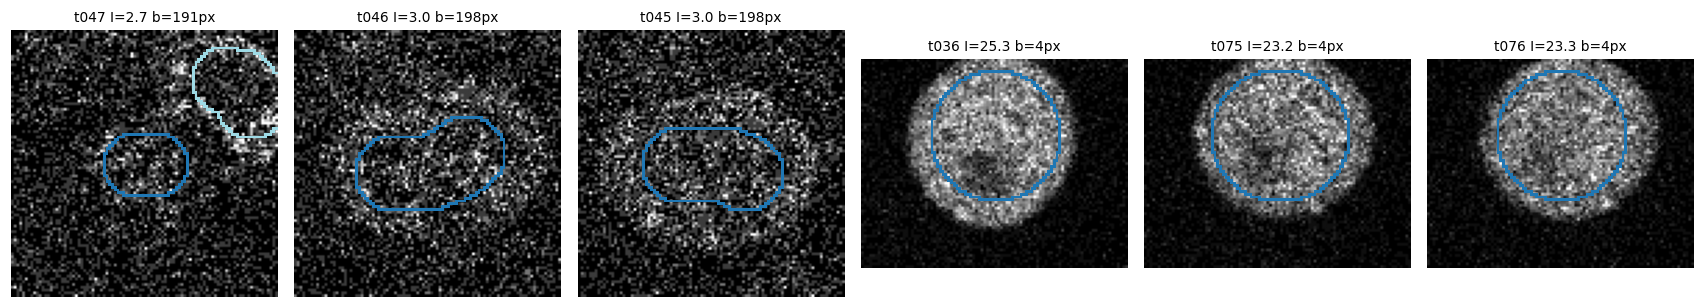

In [38]:
def crop(a, cy, cx, r=48):
    cy, cx = int(cy), int(cx)
    return a[max(cy - r, 0):cy + r, max(cx - r, 0):cx + r]


seq = SEQS[0]
imgs, tra, _, _ = DATA[seq]
g = OBJ[OBJ.seq == seq]
picks = list(g.nsmallest(3, "intensity").itertuples()) + list(g.nsmallest(3, "border").itertuples())
fig, axes = plt.subplots(1, len(picks), figsize=(2.6 * len(picks), 2.8))
for ax, r in zip(axes, picks):
    show_overlay(ax, crop(imgs[r.frame].astype(float), r.cy, r.cx), crop(tra[r.frame], r.cy, r.cx),
                 f"t{r.frame:03d} I={r.intensity:.1f} b={r.border}px")
plt.tight_layout()
plt.savefig(FIGS / "nb_eda_hard_cases.png", bbox_inches="tight")
plt.show()

*Figure 4. Left: the three dimmest gold nuclei. Right: the three closest to the border
(`b` = distance in px).*

## 4. Methods

### 4.1 Pipeline
Tracking-by-detection: **segment each frame independently → link instances across frames →
detect divisions → write a CTC result folder → score with the official `py-ctcmetrics`**.
Any segmenter that outputs `mask###.tif` plugs into the same linker, so every row of the results
table changes exactly one component.

_TODO: insert pipeline diagram (`figs/pipeline.png`)._

### 4.2 Segmentation
| ID | Segmenter | Source | Our work |
|---|---|---|---|
| classical | Otsu threshold + distance-transform watershed | standard | implementation (`src/segment_classical.py`) |
| cpsam | Cellpose 4 `cpsam`, zero-shot | Pachitariu et al., pretrained weights, **not ours** | wrapper and evaluation only |
| cpsam + border | `cpsam`, then drop instances touching the image border | rule | `filter_border_cells` (`src/segmentation_postprocess.py`) |
| **multiscale** | `cpsam` at `diameter=48` + a second pass at `diameter=32`; add a d32 instance only if ≤10% of it overlaps the d48 foreground and ≥200 px remain | Cellpose weights not ours | **ours** (Shu Lian): rule + `merge_multiscale_masks`. Baseline pixels and IDs are never overwritten |
| **temporal** | multiscale, then fill single-frame misses: pair similar objects in t−1 and t+1 (≤24 px apart, area ratio ≥0.6), shift both to the interpolated centre, keep their intersection if it is empty in t, ≥200 px, and brighter than its surroundings (≥1.15×) | — | **ours** (Shu Lian): `src/run_temporal_recovery.py`. No GT is used |
| ours | _TODO: e.g. fine-tuned cpsam / U-Net on GT+ST_ | _TODO_ | _TODO: architecture, loss, training data, hyper-parameters_ |
| oracle | gold TRA markers | CTC annotations | upper bound for linking |

Multi-scale and temporal parameters were chosen on sequence 01 and then frozen for sequence 02.

**Variants tried and rejected** (reported in `plan/SEGMENTATION_IMPROVEMENT.md`, seq 01, official SEG;
not re-run in this notebook because none is in the final pipeline):

| variant | SEG 01 | vs baseline 0.8878 |
|---|---:|---|
| CLAHE preprocessing (clip 1.0) | 0.8876 | no change |
| per-instance erosion 1 px | 0.8804 | worse |
| per-instance dilation 1 px | 0.8650 | worse |
| `cellprob_threshold` = 1.0 / −1.0 | 0.8861 / 0.8773 | no gain / worse |
| **multi-scale recovery** | **0.8984** | **+0.0106** |

Takeaway: once `cpsam` contours are good, reshaping them doesn't help. Recovering whole missed
cells does.

### 4.3 Linking and division detection (our implementation, `src/track.py`)
```
for each frame t:
    IoU matrix between active tracks at t-1 (and up to t-1-max_gap) and masks at t
    Hungarian assignment; drop pairs with IoU < iou_threshold
    division: if an unassigned mask at t lies ≥ containment inside the mother's mask at t-1
              and the two children's area sum ≈ mother's area (ratio in [0.5, 1.8]),
              end the mother at t-1 and start two child tracks with P = mother
    every unmatched mask starts a new track
```
**Optimized IoU-Hungarian linker** (ZIHAO LI, `src/baseline_tracking/track.py`). Same inputs, outputs and
division rule, with two changes:
* **Gate before matching, not after.** Pairs below the IoU threshold are masked out before the
  Hungarian step, and dummy "no match" columns are added. The solver then maximises the number of
  *valid* pairs first, and total IoU second. The original maximises total IoU and filters afterwards,
  which can lose a valid pair. Example with threshold 0.2: scores A→C 0.90, A→D 0.50, B→C 0.40,
  B→D 0.19. The original picks A→C + B→D, then drops B→D, leaving 1 link. Gated assignment picks
  A→D + B→C, giving 2 links.
* **Vectorised IoU.** All label intersections are counted in one pass instead of scanning the image
  per pair, which is 2.3× (01) and 3.0× (02) faster on the same masks.

It also offers two opt-in ablations (hand-set, not trained):
* `hybrid` association: 0.6·IoU after a constant-velocity shift, + 0.3·exp(−dist/30), + 0.1·area
  similarity
* `motion` division rule: daughters near the predicted mother position, balanced areas

**Trackastra** (Gallusser & Weigert, ECCV 2024) is a pretrained transformer that scores candidate links.
A decoder then turns those scores into a graph:
* **Greedy** takes the highest-scoring links first, subject to at most one parent and two children.
* **ILP** (via `motile`) solves for the globally best graph under the same constraints. It is about
  100× slower to decode (≈1 s vs 0.01 s per sequence) and keeps detections that Greedy drops.

The pretrained `general_2d` weights are not ours. **Fine-tuning them on GOWT1 `01` is ours**
(ZIHAO LI, `research/trackastra/` on `feature/trackastra-tracking`). Reported there, not re-run here
because training is heavy:

| fine-tuning experiment | result |
|---|---|
| 8-run grid (epochs 2/10 × samples 16/89 × lr 1e-5/5e-6), GT markers, Greedy, seq 02 | 6 runs tie at TRA 0.99662 / CT 0.8972; the loss differences don't change the graph |
| selected checkpoint | 10 epochs, 89 samples, lr 1e-5, seed 42, best epoch 5 (val loss 0.00089) |
| 3 more seeds (43, 44, 20839) | TRA 0.996612 ± 0.000020, CT 0.8937 ± 0.0060 |
| reproducibility | same seed reproduces byte-for-byte only with the same training cache (crop RNG state is cached) |
| GT markers, `general_2d` vs fine-tuned, Greedy | TRA 0.99654 → 0.99662, CT 0.868 → 0.897 |
| GT markers, `general_2d`, Greedy → ILP | TRA 0.99654 → **0.99936**, CT 0.868 → **0.965**, AOGM 100 → 18.5 |

So with perfect detections the decoder matters more than fine-tuning. §5 tests whether that still
holds with real Cellpose masks.

### 4.4 Hyper-parameters

In [39]:
TRACK_DEFAULTS = dict(iou_threshold=0.2, max_gap=0, detect_divisions=True, division_containment=0.5)
CELLPOSE_MODEL = "cpsam_v2"   # weights used by every team run (Cellpose 4.2.1.1); same for d48 and d32
CELLPOSE_KW = dict(flow_threshold=0.4, cellprob_threshold=0.0, min_size=200)
MULTISCALE = dict(primary_diameter=48, aux_diameter=32, overlap_threshold=0.10, min_area=200)
TEMPORAL = dict(min_area=200, max_two_frame_motion=24, existing_center_radius=15, min_area_ratio=0.60,
                min_shape_iou=0.50, max_occupied_fraction=0.10, min_contrast=1.15)
BORDER_MARGIN = 0          # px; 0 = drop only instances touching the edge
pd.concat({name: pd.Series(d, dtype=object) for name, d in
           {"tracker (ours)": TRACK_DEFAULTS, "cellpose": {"model": CELLPOSE_MODEL, **CELLPOSE_KW},
            "multiscale": MULTISCALE, "temporal": TEMPORAL,
            "border filter": {"margin": BORDER_MARGIN}}.items()}).to_frame("value")

value
tracker (ours) iou_threshold                0.2
               max_gap                        0
               detect_divisions            True
               division_containment         0.5
cellpose       model                   cpsam_v2
               flow_threshold               0.4
               cellprob_threshold           0.0
               min_size                     200
multiscale     primary_diameter              48
               aux_diameter                  32
               overlap_threshold            0.1
               min_area                     200
temporal       min_area                     200
               max_two_frame_motion          24
               existing_center_radius        15
               min_area_ratio               0.6
               min_shape_iou                0.5
               max_occupied_fraction        0.1
               min_contrast                1.15
border filter  margin                         0

## 5. Experiments and results

### 5.1 Segmenters (cached)
Each segmenter writes `runs/nb/seg/<name>/<seq>/mask###.tif`. If a segmenter's dependencies are
missing (e.g. no Cellpose installed), its rows are skipped with a warning rather than crashing the
notebook.

In [40]:
def seg_classical(seq_dir: Path, out: Path):
    from src.segment_classical import segment_sequence
    segment_sequence(seq_dir, out)


def seg_cellpose(diameter: float):
    """Cellpose-SAM at one diameter, same call as the team's scripts (pretrained_model=cpsam_v2)."""
    def run(seq_dir: Path, out: Path):
        import torch
        from cellpose import models
        model = models.CellposeModel(gpu=torch.cuda.is_available(), pretrained_model=CELLPOSE_MODEL)
        for i, p in enumerate(tif_files(seq_dir)):
            m, _, _ = model.eval(tifffile.imread(p), diameter=diameter, **CELLPOSE_KW)
            ctc_io.write_mask(out / f"mask{i:03d}.tif", np.asarray(m).astype(np.uint16))
    return run


def _require(name: str, seq_dir: Path) -> dict[int, np.ndarray]:
    """Masks of another (cached) segmenter, as {frame: array}; ImportError if it can't run."""
    d = get_masks(name, seq_dir.name, seq_dir.parent)
    if d is None:
        raise ImportError(f"needs segmenter {name!r}")
    return {f: ctc_io.read_mask(p) for f, p in ctc_io.list_masks(d).items()}


def seg_border(seq_dir: Path, out: Path):
    from src.segmentation_postprocess import filter_border_cells  # feature/segmentation-improvement
    for i, (_, m) in enumerate(sorted(_require("cpsam", seq_dir).items())):
        ctc_io.write_mask(out / f"mask{i:03d}.tif", filter_border_cells(m, margin=BORDER_MARGIN)[0])


def seg_multiscale(seq_dir: Path, out: Path):
    from src.segmentation_postprocess import merge_multiscale_masks  # feature/segmentation-improvement
    base, small = _require("cpsam", seq_dir), _require("cpsam_d32", seq_dir)
    for i, f in enumerate(sorted(base)):
        merged = merge_multiscale_masks(base[f], small[f], overlap_threshold=MULTISCALE["overlap_threshold"],
                                        min_area=MULTISCALE["min_area"])
        assert np.array_equal(merged[base[f] > 0], base[f][base[f] > 0]), "baseline overwritten"
        ctc_io.write_mask(out / f"mask{i:03d}.tif", merged)


def seg_temporal(seq_dir: Path, out: Path):
    import json
    from types import SimpleNamespace
    from src.run_temporal_recovery import recover_frame  # feature/segmentation-improvement
    multi = [m for _, m in sorted(_require("multiscale", seq_dir).items())]
    imgs = [tifffile.imread(p) for p in tif_files(seq_dir)]
    cfg, events = SimpleNamespace(**TEMPORAL), []
    for i, m in enumerate(multi):
        new = m
        if 0 < i < len(multi) - 1:  # neighbours are the *unrecovered* multiscale masks, as in the script
            new, ev = recover_frame(multi[i - 1], m, multi[i + 1], imgs[i], cfg)
            events += [{**e, "frame": i} for e in ev]
        ctc_io.write_mask(out / f"mask{i:03d}.tif", new)
    (out / "temporal_events.json").write_text(json.dumps({"parameters": TEMPORAL, "events": events}, indent=2))


def seg_oracle(seq_dir: Path, out: Path):
    """Gold TRA markers as 'predictions': isolates linking error from segmentation error."""
    gt = ctc_io.list_masks(seq_dir.with_name(seq_dir.name + "_GT") / "TRA")
    for i, (_, p) in enumerate(gt.items()):
        ctc_io.write_mask(out / f"mask{i:03d}.tif", ctc_io.read_mask(p))


def seg_ours(seq_dir: Path, out: Path):
    """TODO (segmentation owner): our model. Must write out/mask000.tif, mask001.tif, ...
    (16-bit instance labels, 0 = background), one per raw frame, in frame order."""
    raise NotImplementedError("plug the team's segmentation model in here")


SEGMENTERS = {
    "oracle": seg_oracle,
    "classical": seg_classical,
    "cpsam": seg_cellpose(MULTISCALE["primary_diameter"]),
    "cpsam_d32": seg_cellpose(MULTISCALE["aux_diameter"]),  # input to multiscale only
    "cpsam_border": seg_border,
    "multiscale": seg_multiscale,
    "temporal": seg_temporal,
    "ours": seg_ours,
}


def seg_path(name: str, seq: str, ds: Path = DS) -> Path:
    return RUNS / ds.name / "seg" / name / seq


def res_path(exp_id: str, seq: str, ds: Path = DS) -> Path:
    return RUNS / ds.name / "res" / exp_id / f"{seq}_RES"


def get_masks(name: str, seq: str, ds: Path = DS) -> Path | None:
    out = seg_path(name, seq, ds)
    n_frames = len(tif_files(ds / seq))
    if not RECOMPUTE_SEGMENTATION and len(tif_files(out)) == n_frames:
        return out
    if out.exists():
        shutil.rmtree(out)
    out.mkdir(parents=True)
    t0 = time.time()
    try:
        SEGMENTERS[name](ds / seq, out)
    except (ImportError, NotImplementedError) as e:
        warnings.warn(f"segmenter {name!r} unavailable: {e}")
        shutil.rmtree(out)
        return None
    print(f"segmented {ds.name}/{name}/{seq} in {time.time() - t0:.0f}s")
    return out

### 5.2 Linkers
* `iou`: our Hungarian-IoU linker with the division rule (§4.3).
* `iou_opt`: ZIHAO LI's optimized version (gated assignment, vectorised IoU, optional motion terms).
* `trackastra`: Trackastra `general_2d` (pretrained) or ZIHAO LI's GOWT1 fine-tuned checkpoint, decoded
  with **Greedy** or **ILP**. The ILP decoder needs `motile` + `ilpy`. The fine-tuned checkpoint is
  not in the repo: put the folder (`model.pt`, `config.yaml`, `train_config.yaml`) at
  `TRACKASTRA_FINETUNED`, or the rows that use it are skipped.

In [41]:
TRACKASTRA_FINETUNED = Path(os.environ.get("TRACKASTRA_FINETUNED", "models/trackastra_gowt1_finetuned"))


def link_iou(mask_dir: Path, seq_dir: Path, out: Path, **kw):
    masks = {f: ctc_io.read_mask(p) for f, p in ctc_io.list_masks(mask_dir).items()}
    relabelled, table = track_sequence(masks, **{**TRACK_DEFAULTS, **kw})
    save_result(out, relabelled, table)


def link_trackastra(mask_dir: Path, seq_dir: Path, out: Path, model="general_2d", mode="greedy"):
    import torch
    from trackastra.model import Trackastra
    from trackastra.tracking import graph_to_ctc
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if model == "finetuned":
        if not (TRACKASTRA_FINETUNED / "model.pt").is_file():
            raise FileNotFoundError(f"fine-tuned checkpoint not found at {TRACKASTRA_FINETUNED}")
        net = Trackastra.from_folder(TRACKASTRA_FINETUNED, device=device, batch_size=1)
    else:
        net = Trackastra.from_pretrained(model, device=device)
    graph, tracked = net.track_from_disk(seq_dir, mask_dir, mode=mode)
    graph_to_ctc(graph, tracked, outdir=out)
    # rename Trackastra's GT-style names to the CTC result convention
    (out / "man_track.txt").rename(out / "res_track.txt")
    for i, p in enumerate(sorted(out.glob("man_track*.tif"))):
        p.rename(out / f"mask{i:03d}.tif")


def link_iou_opt(mask_dir: Path, seq_dir: Path, out: Path, **kw):
    """ZIHAO LI's optimized linker (feature/baseline-tracking). Defaults = gated_iou_overlap_div."""
    from src.baseline_tracking.track import track_sequence as track_opt
    from src.baseline_tracking.run_track import save_result as save_opt
    masks = {f: ctc_io.read_mask(p) for f, p in ctc_io.list_masks(mask_dir).items()}
    cfg = dict(iou_threshold=0.2, max_gap=0, detect_divisions=True, division_containment=0.5,
               area_ratio_range=(0.5, 1.8), association="iou", max_distance=30.0,
               division_mode="overlap", division_distance=2.0)
    relabelled, table = track_opt(masks, **{**cfg, **kw})
    save_opt(out, relabelled, table)


LINKERS = {"iou": link_iou, "iou_opt": link_iou_opt, "trackastra": link_trackastra}

### 5.3 Experiment registry
One row per experiment, and each row changes one thing relative to its reference. Add rows here.
Set `on=False` to skip a row without deleting it. **S1-ilp is the configuration recommended for the
headline result** (highest TRA/OP_CTB in ZIHAO LI's runs on GOWT1 02 and both HeLa sequences). S1-astra
(Greedy) is the companion row for track completeness (CT, TF, BC).

In [42]:
GREEDY, ILP = dict(mode="greedy"), dict(mode="ilp")
FT = dict(model="finetuned")
EXPERIMENTS = [
    # id           segmenter    linker        linker kwargs                       what it shows
    dict(id="B0", seg="oracle", link="iou", kw={}, note="linking upper bound (gold markers)", on=True),
    dict(id="B1", seg="classical", link="iou", kw={}, note="classical floor", on=True),
    dict(id="B2", seg="cpsam", link="iou", kw={}, note="zero-shot SOTA segmenter", on=True),
    dict(id="B2-nodiv", seg="cpsam", link="iou", kw=dict(detect_divisions=False),
         note="contribution of division rule", on=True),
    # ZIHAO LI's linker ablations, same cpsam masks as B2 (his names in brackets)
    dict(id="L1", seg="cpsam", link="iou_opt", kw={}, note="optimized linker vs B2 [gated_iou_overlap_div]",
         on=True),
    dict(id="L1-nodiv", seg="cpsam", link="iou_opt", kw=dict(detect_divisions=False),
         note="divisions off [gated_iou_no_div]", on=True),
    dict(id="L1-hybrid", seg="cpsam", link="iou_opt", kw=dict(association="hybrid", detect_divisions=False),
         note="motion-aware association [hybrid_no_div]", on=True),
    dict(id="L1-motiondiv", seg="cpsam", link="iou_opt", kw=dict(division_mode="motion"),
         note="geometric division rule [iou_motion_div]", on=True),
    dict(id="L1-hybrid-motion", seg="cpsam", link="iou_opt",
         kw=dict(association="hybrid", division_mode="motion"), note="both [hybrid_motion_div]", on=True),
    dict(id="B2-astra", seg="cpsam", link="trackastra", kw=GREEDY, note="SOTA linker, same masks", on=True),
    dict(id="B2-ilp", seg="cpsam", link="trackastra", kw=ILP, note="ILP vs Greedy decoder", on=True),
    dict(id="S0", seg="cpsam_border", link="iou", kw={}, note="border filter vs B2", on=True),
    dict(id="S1", seg="multiscale", link="iou", kw={}, note="multi-scale recovery vs B2", on=True),
    dict(id="S1-L1-nodiv", seg="multiscale", link="iou_opt", kw=dict(detect_divisions=False),
         note="best simple pipeline: multi-scale + optimized linker, no divisions (new combination)", on=True),
    dict(id="S1-astra", seg="multiscale", link="trackastra", kw=GREEDY, note="multi-scale vs B2-astra", on=True),
    dict(id="S1-ilp", seg="multiscale", link="trackastra", kw=ILP, note="★ main config: multi-scale + ILP",
         on=True),
    dict(id="S1-ft", seg="multiscale", link="trackastra", kw={**FT, **GREEDY},
         note="fine-tuned Trackastra vs S1-astra", on=True),
    dict(id="S1-ft-ilp", seg="multiscale", link="trackastra", kw={**FT, **ILP},
         note="fine-tuned Trackastra vs S1-ilp", on=True),
    dict(id="S2-astra", seg="temporal", link="trackastra", kw=GREEDY, note="+ temporal recovery vs S1-astra",
         on=True),
    dict(id="M1", seg="ours", link="iou", kw={}, note="TODO our segmenter", on=True),
]
pd.DataFrame(EXPERIMENTS).set_index("id")[["seg", "link", "kw", "note", "on"]]

,seg,link,kw,note,on
id,,,,,
B0,oracle,iou,{},linking upper bound (gold markers),True
B1,classical,iou,{},classical floor,True
B2,cpsam,iou,{},zero-shot SOTA segmenter,True
B2-nodiv,cpsam,iou,{'detect_divisions': False},contribution of division rule,True
L1,cpsam,iou_opt,{},optimized linker vs B2 [gated_iou_overlap_div],True
L1-nodiv,cpsam,iou_opt,{'detect_divisions': False},divisions off [gated_iou_no_div],True
L1-hybrid,cpsam,iou_opt,"{'association': 'hybrid', 'detect_divisions': ...",motion-aware association [hybrid_no_div],True
L1-motiondiv,cpsam,iou_opt,{'division_mode': 'motion'},geometric division rule [iou_motion_div],True
L1-hybrid-motion,cpsam,iou_opt,"{'association': 'hybrid', 'division_mode': 'mo...",both [hybrid_motion_div],True


### 5.4 Run and score
Metrics come from `ctc_metrics.evaluate_sequence` (official implementation), including the six
AOGM error terms, CT (complete tracks), TF (track fractions) and BC(0) (exact-frame division
accuracy). Scores are cached in `results/metrics.csv`.

In [43]:
METRIC_CACHE = RESULTS / "metrics.csv"
cache = pd.read_csv(METRIC_CACHE, dtype={"seq": str}) \
    if METRIC_CACHE.exists() and not RECOMPUTE_METRICS else pd.DataFrame()
KEEP = ["DET", "SEG", "TRA", "CT", "TF", "BC(0)", "AOGM", "AOGM_0",
        *[f"AOGM_{k}" for k in WEIGHTS], "gt_divisions", "tp_div(0)", "fp_div(0)", "fn_div(0)"]


def run_experiment(exp: dict, seq: str, ds: Path = DS) -> dict | None:
    key = f"{ds.name}|{exp['id']}|{seq}"
    if not cache.empty and key in set(cache["key"]) and not (RECOMPUTE_TRACKING or RECOMPUTE_SEGMENTATION):
        return cache.set_index("key").loc[key].to_dict() | {"key": key}
    mask_dir = get_masks(exp["seg"], seq, ds)
    if mask_dir is None:
        return None
    res = res_path(exp["id"], seq, ds)
    if RECOMPUTE_TRACKING or not (res / "res_track.txt").exists():
        if res.exists():
            shutil.rmtree(res)
        t0 = time.time()
        try:
            LINKERS[exp["link"]](mask_dir, ds / seq, res, **exp["kw"])
        except (ImportError, FileNotFoundError, subprocess.CalledProcessError) as e:  # missing branch/dep
            warnings.warn(f"{exp['id']}: linker {exp['link']!r} unavailable: {e}")
            if res.exists():
                shutil.rmtree(res)
            return None
        link_s = time.time() - t0
        (res / "link_seconds.txt").write_text(f"{link_s:.3f}")
        print(f"linked {ds.name}/{exp['id']}/{seq} in {link_s:.0f}s")
    r = decompose(ds / f"{seq}_GT", res)
    row = {k: r.get(k) for k in KEEP}
    t_file = res / "link_seconds.txt"
    row["link_seconds"] = float(t_file.read_text()) if t_file.exists() else np.nan
    row["n_tracks"] = len(ctc_io.read_track_table(res / "res_track.txt"))
    return {"key": key, "dataset": ds.name, "id": exp["id"], "seq": seq, **row}


def run_all(experiments, seqs, ds: Path = DS) -> pd.DataFrame:
    out = []
    for exp in [e for e in experiments if e["on"]]:
        for seq in seqs:
            r = run_experiment(exp, seq, ds)
            if r is not None:
                out.append(r)
                print(f"{exp['id']:>10} {seq}: DET {r['DET']:.4f}  SEG {r['SEG']:.4f}  TRA {r['TRA']:.4f}")
    return pd.DataFrame(out)


def save_metrics(df: pd.DataFrame):
    """Merge into the cache file without dropping other datasets' rows."""
    if df.empty:
        return
    old = pd.read_csv(METRIC_CACHE, dtype={"seq": str}) if METRIC_CACHE.exists() else pd.DataFrame()
    keep = old[~old["key"].isin(df["key"])] if len(old) else old
    pd.concat([keep, df], ignore_index=True).to_csv(METRIC_CACHE, index=False)


results = run_all(EXPERIMENTS, SEQS)
save_metrics(results)

        B0 01: DET 1.0000  SEG 0.4836  TRA 0.9988
        B0 02: DET 1.0000  SEG 0.3540  TRA 0.9980
        B1 01: DET 0.4949  SEG 0.2615  TRA 0.4914
        B1 02: DET 0.4079  SEG 0.4465  TRA 0.4050
        B2 01: DET 0.9819  SEG 0.8878  TRA 0.9821
        B2 02: DET 0.9569  SEG 0.9193  TRA 0.9573
  B2-nodiv 01: DET 0.9819  SEG 0.8878  TRA 0.9821
  B2-nodiv 02: DET 0.9569  SEG 0.9193  TRA 0.9576
        L1 01: DET 0.9819  SEG 0.8878  TRA 0.9821
        L1 02: DET 0.9569  SEG 0.9193  TRA 0.9573
  L1-nodiv 01: DET 0.9819  SEG 0.8878  TRA 0.9821
  L1-nodiv 02: DET 0.9569  SEG 0.9193  TRA 0.9576
 L1-hybrid 01: DET 0.9819  SEG 0.8878  TRA 0.9821
 L1-hybrid 02: DET 0.9569  SEG 0.9193  TRA 0.9576
L1-motiondiv 01: DET 0.9819  SEG 0.8878  TRA 0.9822
L1-motiondiv 02: DET 0.9569  SEG 0.9193  TRA 0.9576
L1-hybrid-motion 01: DET 0.9819  SEG 0.8878  TRA 0.9822
L1-hybrid-motion 02: DET 0.9569  SEG 0.9193  TRA 0.9576
  B2-astra 01: DET 0.9819  SEG 0.8878  TRA 0.9823
  B2-astra 02: DET 0.9561  SEG 0.9

/tmp/ipykernel_388/420385146.py:23: UserWarning: S1-ft: linker 'trackastra' unavailable: fine-tuned checkpoint not found at models/trackastra_gowt1_finetuned
  warnings.warn(f"{exp['id']}: linker {exp['link']!r} unavailable: {e}")
/tmp/ipykernel_388/420385146.py:23: UserWarning: S1-ft-ilp: linker 'trackastra' unavailable: fine-tuned checkpoint not found at models/trackastra_gowt1_finetuned
  warnings.warn(f"{exp['id']}: linker {exp['link']!r} unavailable: {e}")
/tmp/ipykernel_388/1414727825.py:103: UserWarning: segmenter 'ours' unavailable: plug the team's segmentation model in here
  warnings.warn(f"segmenter {name!r} unavailable: {e}")


### 5.5 Main results table

In [44]:
results["OP_CTB"] = (results.SEG + results.TRA) / 2
order = [e["id"] for e in EXPERIMENTS if e["id"] in set(results.id)]
main = results.pivot(index="id", columns="seq", values=["DET", "SEG", "TRA", "OP_CTB"]).loc[order]
for m in ["DET", "SEG", "TRA", "OP_CTB"]:
    main[(m, "mean")] = main[m].mean(axis=1)
main = main.sort_index(axis=1, level=0, sort_remaining=False)
main.to_csv(RESULTS / "main_table.csv")
main.style.format("{:.4f}").highlight_max(axis=0, props="font-weight:bold") \
    .set_caption("Table 4. Official CTC metrics per sequence and mean (higher is better). "
                 "B0 uses gold markers and is an upper bound, not a competitor.")

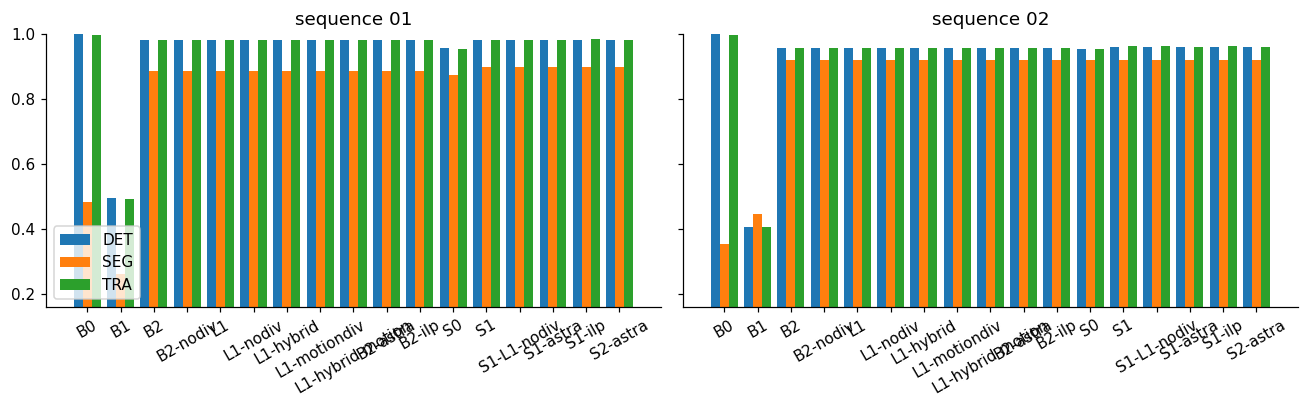

In [45]:
fig, axes = plt.subplots(1, len(SEQS), figsize=(6 * len(SEQS), 3.8), sharey=True)
for ax, seq in zip(np.atleast_1d(axes), SEQS):
    sub = results[results.seq == seq].set_index("id").loc[[i for i in order if i in set(results[results.seq == seq].id)]]
    x = np.arange(len(sub))
    for j, m in enumerate(["DET", "SEG", "TRA"]):
        ax.bar(x + (j - 1) * 0.27, sub[m], 0.27, label=m)
    ax.set_xticks(x, sub.index, rotation=30)
    ax.set_ylim(max(0, results[["DET", "SEG", "TRA"]].min().min() - 0.1), 1.0)
    ax.set_title(f"sequence {seq}")
np.atleast_1d(axes)[0].legend(loc="lower left")
plt.tight_layout()
plt.savefig(FIGS / "nb_results_bars.png", bbox_inches="tight")
plt.show()

*Figure 5. Headline metrics per experiment.*

### 5.6 What the TRA error is made of
TRA differences in the fourth decimal hide very different error mixes. Decomposing AOGM into its
weighted terms says *what* to fix.

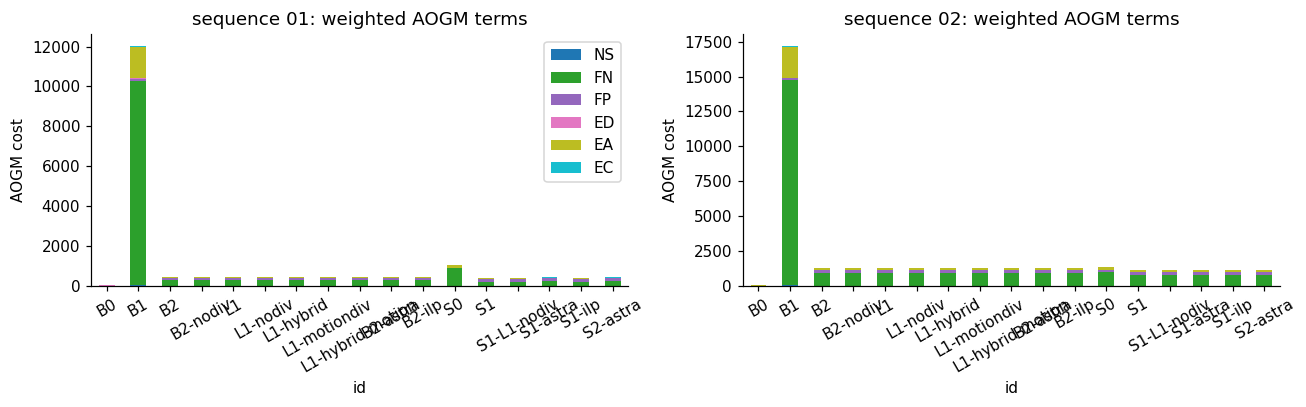

CT      TF  BC(0)  gt_divisions  tp_div(0)  \
id               seq                                                   
B0               01   0.6567  0.9331    0.0             2          0   
                 02   0.6043  0.9398    0.0             4          0   
B1               01   0.0349  0.4483    0.0             2          0   
                 02   0.0000  0.5272    0.0             4          0   
B2               01   0.5507  0.9470    0.0             2          0   
                 02   0.2941  0.9142    0.0             4          0   
B2-nodiv         01   0.5507  0.9470    0.0             2          0   
                 02   0.3125  0.9216    0.0             4          0   
L1               01   0.5507  0.9470    0.0             2          0   
                 02   0.2941  0.9142    0.0             4          0   
L1-nodiv         01   0.5507  0.9470    0.0             2          0   
                 02   0.3125  0.9216    0.0             4          0   
L1-hybrid        01   0.5507  0.9470    0.0             2          0   
                 02   0.3101  0.9216    0.0             4          0   
L1-motiondiv     01   0.5429  0.9470    0.0             2          0   
                 02   0.3101  0.9216    0.0             4          0   
L1-hybrid-motion 01   0.5429  0.9470    0.0             2          0   
                 02   0.3077  0.9216    0.0             4          0   
B2-astra         01   0.6316  0.9723    0.0             2          0   
                 02   0.3276  0.9304    0.0             4          0   
B2-ilp           01   0.5373  0.9731    0.0             2          0   
                 02   0.3030  0.9142    0.0             4          0   
S0               01   0.4304  0.9211    0.0             2          0   
                 02   0.2817  0.8892    0.0             4          0   
S1               01   0.5067  0.9186    0.0             2          0   
                 02   0.3404  0.9258    0.0             4          0   
S1-L1-nodiv      01   0.5067  0.9186    0.0             2          0   
                 02   0.3609  0.9329    0.0             4          0   
S1-astra         01   0.5373  0.9721    0.0             2          0   
                 02   0.3729  0.9559    0.0             4          0   
S1-ilp           01   0.4932  0.9433    0.0             2          0   
                 02   0.3382  0.9258    0.0             4          0   
S2-astra         01   0.5455  0.9721    0.0             2          0   
                 02   0.3793  0.9587    0.0             4          0   

                      fn_div(0)  fp_div(0)  n_tracks  gt_tracks  
id               seq                                             
B0               01           2          0        39         28  
                 02           4          0        81         58  
B1               01           2         57       144         28  
                 02           4         44       119         58  
B2               01           2          0        41         28  
                 02           4          8        78         58  
B2-nodiv         01           2          0        41         28  
                 02           4          0        70         58  
L1               01           2          0        41         28  
                 02           4          8        78         58  
L1-nodiv         01           2          0        41         28  
                 02           4          0        70         58  
L1-hybrid        01           2          0        41         28  
                 02           4          0        71         58  
L1-motiondiv     01           2          1        42         28  
                 02           4          1        71         58  
L1-hybrid-motion 01           2          1        42         28  
                 02           4          1        72         58  
B2-astra         01           2          0        29         28  
                 02           4          1     

In [46]:
terms = list(WEIGHTS)
cost = results.set_index(["id", "seq"])[[f"AOGM_{k}" for k in terms]].fillna(0)
cost = cost * np.array([WEIGHTS[k] for k in terms])
cost.columns = terms
fig, axes = plt.subplots(1, len(SEQS), figsize=(6 * len(SEQS), 3.8))
for ax, seq in zip(np.atleast_1d(axes), SEQS):
    c = cost.xs(seq, level="seq").reindex([i for i in order if (i, seq) in cost.index])
    c.plot.bar(stacked=True, ax=ax, colormap="tab10", rot=30, legend=ax is np.atleast_1d(axes)[0])
    ax.set(title=f"sequence {seq}: weighted AOGM terms", ylabel="AOGM cost")
plt.tight_layout()
plt.savefig(FIGS / "nb_aogm_terms.png", bbox_inches="tight")
plt.show()

lineage = results.set_index(["id", "seq"])[["CT", "TF", "BC(0)", "gt_divisions", "tp_div(0)",
                                            "fn_div(0)", "fp_div(0)", "n_tracks"]]
gt_tracks = {s: len(DATA[s][3]) for s in SEQS}
lineage["gt_tracks"] = [gt_tracks[s] for _, s in lineage.index]
lineage.round(4)

*Figure 6 / Table 5. AOGM decomposition and lineage metrics.* `tp/fn/fp_div(0)` = divisions
correct / missed / spurious at exact frame. Compare `n_tracks` with `gt_tracks`: more tracks than
truth means fragmentation (missing links or spurious detections starting new tracks).

#### Linker comparison on identical masks

In [47]:
L_IDS = ["B2", "B2-nodiv", "L1", "L1-nodiv", "L1-hybrid", "L1-motiondiv", "L1-hybrid-motion", "B2-astra", "B2-ilp"]
lc = results[results.id.isin(L_IDS)].set_index(["id", "seq"])
if len(lc):
    lc = lc[["TRA", "CT", "TF", "AOGM", "tp_div(0)", "fp_div(0)", "n_tracks", "link_seconds"]]
    lc = lc.reindex([(i, s) for i in L_IDS for s in SEQS if (i, s) in lc.index])
    display(lc.style.format({"TRA": "{:.5f}", "CT": "{:.4f}", "TF": "{:.4f}", "AOGM": "{:.1f}",
                             "link_seconds": "{:.1f}"})
            .set_caption("Table 5b. All linkers on the same cpsam masks. link_seconds = tracking only, "
                         "this machine, one run."))

*Table 5b.* ZIHAO LI's reported findings (Mac, CPU tracking): L1 matches B2 exactly on both sequences
and is 2.3× / 3.0× faster (17.0 → 7.3 s, 26.9 → 8.9 s). Switching divisions off removes 9 spurious
divisions on 02 (TRA 0.95758 → 0.95786, CT 0.286 → 0.305). The hybrid and motion ablations don't help
consistently, and the geometric division rule adds a false division on 01. **No linker finds a single
true GOWT1 division.**

### 5.7 Reproduction check
Numbers from the team's experiment reports: `plan/RESULTS_cpsam.md`, `plan/SEGMENTATION_IMPROVEMENT.md`,
`plan/TEMPORAL_RECOVERY_RESULTS.md` (Shu), and `research/trackastra/reports/integrated_conclusion.md`
(ZIHAO LI, seq 02 only; ILP and fine-tuned rows), and `plan/RESULTS_baseline_tracking.md` (ZIHAO LI,
L-rows, run on a Mac). All were run on CUDA with Cellpose 4.2.1.1 `cpsam_v2`. A difference of a few 1e-4 is expected across devices (see README, *Reproducibility*).
Anything larger means the masks or settings differ, so investigate it before the number goes into the
report.

In [48]:
REPORTED = {  # (id, seq): (DET, SEG, TRA)
    ("B2", "01"): (0.9818, 0.8878, 0.9821), ("B2", "02"): (0.9570, 0.9192, 0.9574),
    ("B2-astra", "01"): (0.9818, 0.8878, 0.9822), ("B2-astra", "02"): (0.9561, 0.9193, 0.9569),
    ("S1-astra", "01"): (0.9824, 0.8984, 0.9829), ("S1-astra", "02"): (0.9600, 0.9193, 0.9611),
    ("S2-astra", "01"): (0.9823, 0.8984, 0.9828), ("S2-astra", "02"): (0.9603, 0.9193, 0.9615),
    # ZIHAO LI, linker study (plan/RESULTS_baseline_tracking.md). Mac MPS segmentation, so his B2 masks
    # differ slightly from the CUDA ones on 02 (82 vs 76 tracks): compare L-rows with B2 *in this run*.
    ("L1", "01"): (0.98188, 0.88791, 0.98214), ("L1", "02"): (0.95725, 0.91930, 0.95758),
    ("L1-nodiv", "01"): (0.98188, 0.88791, 0.98214), ("L1-nodiv", "02"): (0.95725, 0.91930, 0.95786),
    ("L1-hybrid", "01"): (0.98188, 0.88791, 0.98214), ("L1-hybrid", "02"): (0.95725, 0.91930, 0.95786),
    ("L1-motiondiv", "01"): (0.98188, 0.88791, 0.98216), ("L1-motiondiv", "02"): (0.95725, 0.91930, 0.95786),
    # ZIHAO LI (tuzzzzi), GOWT1 02 (integrated_conclusion.md, table 7)
    ("B2-ilp", "02"): (0.95697, 0.91923, 0.95751), ("S1-ilp", "02"): (0.96118, 0.91923, 0.96198),
    ("S1-ft", "02"): (0.96039, 0.91923, 0.96135), ("S1-ft-ilp", "02"): (0.96118, 0.91923, 0.96184),
}
TOL = 5e-4


def reproduction_check(df: pd.DataFrame, reported: dict) -> pd.DataFrame:
    out = []
    for (i, s), vals in reported.items():
        hit = df[(df.id == i) & (df.seq == s)] if len(df) else df
        for m, v in zip(["DET", "SEG", "TRA"], vals):
            got = float(hit[m].iloc[0]) if len(hit) else np.nan
            out.append(dict(id=i, seq=s, metric=m, reported=v, notebook=got, diff=got - v,
                            status="not run" if np.isnan(got) else ("ok" if abs(got - v) <= TOL else "CHECK")))
    out = pd.DataFrame(out)
    ran = out.dropna(subset=["notebook"])
    if len(ran):
        display(ran.pivot_table(index=["id", "seq"], columns="metric", values="diff").round(4))
    print("status:", out.status.value_counts().to_dict())
    return out


rep = reproduction_check(results, REPORTED)

metric               DET     SEG     TRA
id           seq                        
B2           01   0.0001  0.0000  0.0000
             02  -0.0001  0.0001 -0.0001
B2-astra     01   0.0001  0.0000  0.0001
             02   0.0000 -0.0000 -0.0000
B2-ilp       02  -0.0000  0.0001 -0.0000
L1           01  -0.0000 -0.0001  0.0000
             02  -0.0003 -0.0000 -0.0002
L1-hybrid    01  -0.0000 -0.0001  0.0000
             02  -0.0003 -0.0000 -0.0003
L1-motiondiv 01  -0.0000 -0.0001  0.0000
             02  -0.0003 -0.0000 -0.0003
L1-nodiv     01  -0.0000 -0.0001  0.0000
             02  -0.0003 -0.0000 -0.0003
S1-astra     01   0.0001 -0.0000  0.0000
             02   0.0004 -0.0000  0.0004
S1-ilp       02   0.0003  0.0001  0.0003
S2-astra     01   0.0001 -0.0000  0.0001
             02   0.0004 -0.0000  0.0003

status: {'ok': 54, 'not run': 6}


*Table 6. Notebook minus reported value. `not run` means that experiment was skipped in this run.*

### 5.8 What the recovery steps actually added
Multi-scale and temporal recovery only ever **add** instances (baseline pixels are never touched),
so the effect can be counted directly. Shu's reported counts: multiscale +52 / +37 instances on
01 / 02; temporal a further +3 / +3.

added  frames_changed
seq step                                        
01  cpsam → multiscale        52              48
    multiscale → temporal      2               2
02  cpsam → multiscale        39              31
    multiscale → temporal      3               3

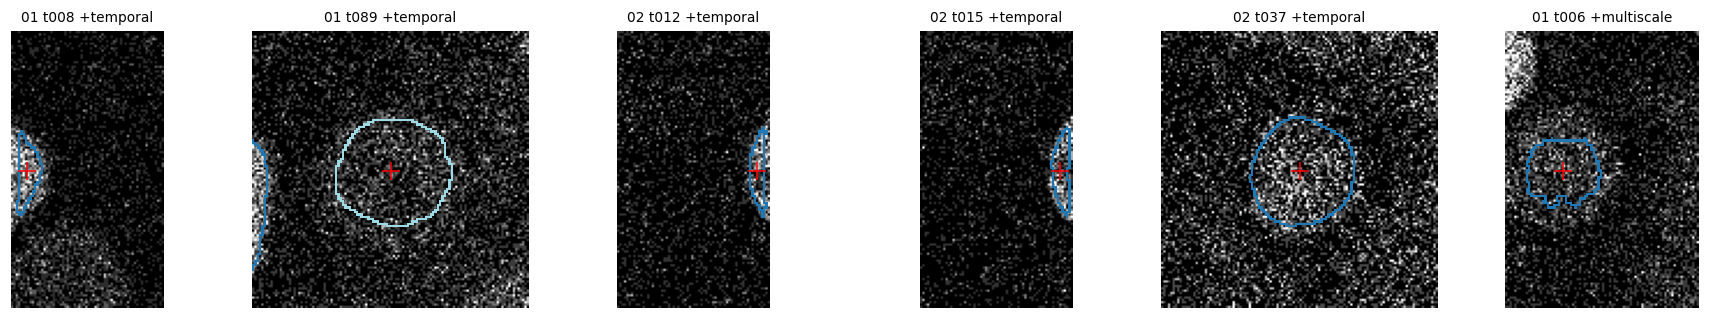

In [49]:
def label_sets(name, seq):
    d = seg_path(name, seq)
    return {f: set(np.unique(ctc_io.read_mask(p))) - {0} for f, p in ctc_io.list_masks(d).items()} \
        if len(tif_files(d)) else None


added_rows, examples = [], []
for seq in SEQS:
    chain = [("cpsam", "multiscale"), ("multiscale", "temporal")]
    for before, after in chain:
        a, b = label_sets(before, seq), label_sets(after, seq)
        if a is None or b is None:
            continue
        per_frame = {f: len(b[f] - a[f]) for f in b}
        added_rows.append(dict(seq=seq, step=f"{before} → {after}", added=sum(per_frame.values()),
                               frames_changed=sum(v > 0 for v in per_frame.values())))
        changed = [f for f, n in per_frame.items() if n]
        # up to 3 examples per step, spread over the sequence rather than consecutive frames
        for f in [changed[k] for k in np.linspace(0, len(changed) - 1, min(3, len(changed))).astype(int)]:
            bm = ctc_io.read_mask(ctc_io.list_masks(seg_path(after, seq))[f])
            lab = sorted(b[f] - a[f])[0]
            cy, cx = ndimage.center_of_mass(bm == lab)
            examples.append((seq, f, after, cy, cx, bm))
examples = [e for e in examples if e[2] == "temporal"] + [e for e in examples if e[2] != "temporal"]
examples = examples[:6]
if added_rows:
    display(pd.DataFrame(added_rows).set_index(["seq", "step"]))
if examples:
    fig, axes = plt.subplots(1, len(examples), figsize=(2.8 * len(examples), 3))
    for ax, (seq, f, name, cy, cx, bm) in zip(np.atleast_1d(axes), examples):
        img = DATA[seq][0][f].astype(float)
        show_overlay(ax, crop(img, cy, cx, 60), crop(bm, cy, cx, 60), f"{seq} t{f:03d} +{name}")
        ax.plot(min(cx, 60), min(cy, 60), "r+", ms=12)  # position inside the crop
    plt.tight_layout()
    plt.savefig(FIGS / "nb_recovered_cells.png", bbox_inches="tight")
    plt.show()
elif added_rows:
    print("the recovery steps added no instances in this run")
else:
    print("recovery masks not available in this run (needs Cellpose and the "
          "feature/segmentation-improvement modules)")

*Table 7 / Figure 7. Instances added by each recovery step. Red cross = the added instance.
For the report, check whether each one is a real missed nucleus or a false positive. Shu found that
several d32 additions do not reach IoU ≥ 0.5 with a GT marker, but official DET still rose.*

### 5.9 Qualitative comparison

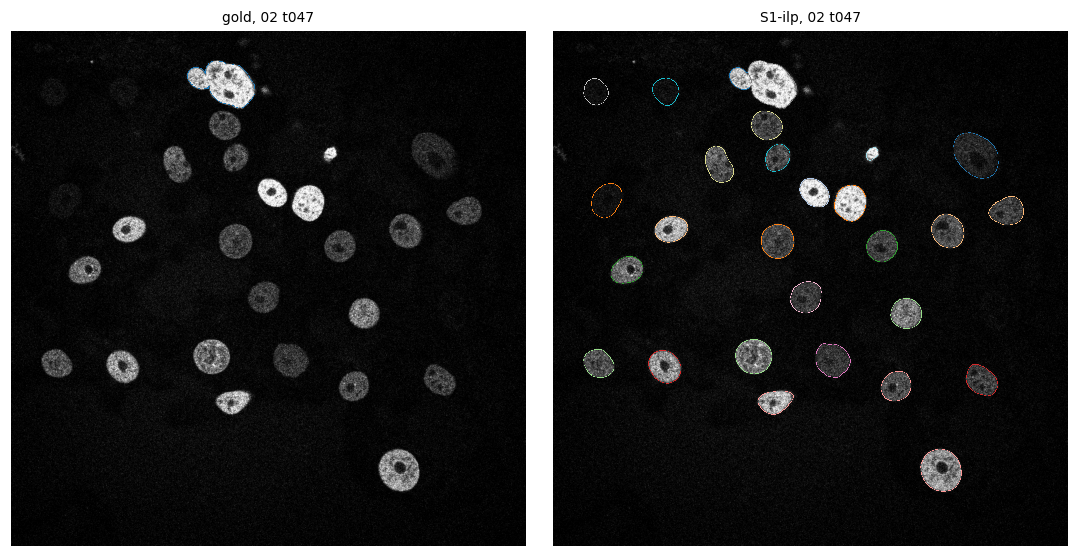

In [50]:
BEST = max((i for i in order if i != "B0"), key=lambda i: results[results.id == i].TRA.mean(),
           default=order[0])
seq = SEQS[-1]
imgs, tra, seg, _ = DATA[seq]
frame = sorted(seg)[len(seg) // 2] if seg else sorted(tra)[len(tra) // 2]
res_dir = res_path(BEST, seq)
first = min(imgs)
pred = ctc_io.read_mask(res_dir / f"mask{frame - first:03d}.tif")
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
show_overlay(axes[0], imgs[frame].astype(float), seg.get(frame, tra[frame]), f"gold, {seq} t{frame:03d}")
show_overlay(axes[1], imgs[frame].astype(float), pred, f"{BEST}, {seq} t{frame:03d}")
plt.tight_layout()
plt.savefig(FIGS / "nb_qualitative.png", bbox_inches="tight")
plt.show()

*Figure 8. Gold annotation vs the best non-oracle experiment on a held-out frame.*

### 5.10 Cross-dataset evaluation: Fluo-N2DL-HeLa
Does the pipeline chosen on GOWT1 transfer to a different nucleus dataset **without any retuning**?
`Fluo-N2DL-HeLa` (H2B-GFP HeLa nuclei, 700×1100) is the same imaging modality as GOWT1, but it is
much denser and divides far more often. Both labelled training sequences are used **for scoring
only**: same Cellpose weights and diameters (48/32), same merge rule, same Trackastra weights. The
fine-tuned checkpoint was trained on GOWT1 `01`, so on HeLa it is a transfer test. Note that
`general_2d`'s training list includes `DIC-C2DH-HeLa` (a different modality) but not this dataset.
Results reported by ZIHAO LI in `research/trackastra/reports/hela_cross_dataset.md`.

Download `Fluo-N2DL-HeLa.zip` from the same CTC page into `data/Fluo-N2DL-HeLa/`. The section is
skipped if the folder is missing. Cost: two Cellpose passes over 184 frames, plus ILP on about 8.5k
and 27k nodes.

In [51]:
HELA_IDS = ["B2-astra", "B2-ilp", "S1-astra", "S1-ilp", "S1-ft", "S1-ft-ilp"]
HELA_REPORTED = {  # ZIHAO LI, hela_cross_dataset.md: (DET, SEG, TRA)
    ("B2-astra", "01"): (0.92160, 0.71606, 0.91904), ("B2-astra", "02"): (0.94937, 0.82845, 0.94662),
    ("B2-ilp", "01"): (0.92535, 0.71934, 0.92216), ("B2-ilp", "02"): (0.95059, 0.82933, 0.94734),
    ("S1-astra", "01"): (0.93051, 0.72090, 0.92806), ("S1-astra", "02"): (0.95691, 0.83591, 0.95430),
    ("S1-ilp", "01"): (0.93379, 0.72419, 0.93070), ("S1-ilp", "02"): (0.95804, 0.83591, 0.95500),
    ("S1-ft", "01"): (0.93086, 0.72090, 0.92816), ("S1-ft", "02"): (0.95719, 0.83591, 0.95435),
    ("S1-ft-ilp", "01"): (0.93379, 0.72419, 0.93012), ("S1-ft-ilp", "02"): (0.95804, 0.83591, 0.95457),
}
RUN_HELA = HELA_DS.is_dir()
hela = pd.DataFrame()
if RUN_HELA:
    # data inventory, side by side with GOWT1
    inv = []
    for ds in (DS, HELA_DS):
        for seq in SEQS:
            tab = ctc_io.read_track_table(ds / f"{seq}_GT" / "TRA" / "man_track.txt")
            tra = ctc_io.list_masks(ds / f"{seq}_GT" / "TRA")
            n_obj = sum(len(np.unique(ctc_io.read_mask(p))) - 1 for p in tra.values())
            img0 = tifffile.imread(tif_files(ds / seq)[0])
            inv.append({"dataset": ds.name, "seq": seq, "frames": len(tra),
                        "shape": "×".join(map(str, img0.shape)), "GT TRA objects": n_obj,
                        "cells / frame": round(n_obj / len(tra), 1),
                        "GT SEG frames": len(tif_files(ds / f"{seq}_GT" / "SEG")),
                        "GT divisions": len({int(x) for x in tab[:, 3] if x > 0})})
    display(pd.DataFrame(inv).set_index(["dataset", "seq"]))
    hela = run_all([e for e in EXPERIMENTS if e["id"] in HELA_IDS], SEQS, HELA_DS)
    save_metrics(hela)
else:
    print(f"skipping HeLa: {HELA_DS.resolve()} not found")

frames      shape  GT TRA objects  cells / frame  \
dataset         seq                                                     
Fluo-N2DH-GOWT1 01       92  1024×1024            2058           22.4   
                02       92  1024×1024            2517           27.4   
Fluo-N2DL-HeLa  01       92   700×1100            8639           93.9   
                02       92   700×1100           25420          276.3   

                     GT SEG frames  GT divisions  
dataset         seq                               
Fluo-N2DH-GOWT1 01              30             3  
                02              20             9  
Fluo-N2DL-HeLa  01              28            94  
                02               8           212

  B2-astra 01: DET 0.9208  SEG 0.7160  TRA 0.9182
  B2-astra 02: DET 0.9496  SEG 0.8283  TRA 0.9469
    B2-ilp 01: DET 0.9245  SEG 0.7178  TRA 0.9213
    B2-ilp 02: DET 0.9508  SEG 0.8292  TRA 0.9476
  S1-astra 01: DET 0.9299  SEG 0.7209  TRA 0.9274
segmented Fluo-N2DL-HeLa/cpsam_d32/02 in 678s
segmented Fluo-N2DL-HeLa/multiscale/02 in 705s
/root/.local/share/trackastra/models/general_2d already downloaded, skipping.


Saving masks: 100%|██████████| 92/92 [00:00<00:00, 128.67it/s]


linked Fluo-N2DL-HeLa/S1-astra/02 in 30s
  S1-astra 02: DET 0.9568  SEG 0.8358  TRA 0.9542
/root/.local/share/trackastra/models/general_2d already downloaded, skipping.


Computing associations: 100%|██████████| 23/23 [00:01<00:00, 12.62it/s]



Candidate graph		8620 nodes	8406 edges
Solution graph		8620 nodes	8369 edges


... (3 outputs left out)


Candidate graph		27124 nodes	26724 edges
Solution graph		27124 nodes	26569 edges


Saving masks: 100%|██████████| 92/92 [00:00<00:00, 173.66it/s]


linked Fluo-N2DL-HeLa/S1-ilp/02 in 47s
    S1-ilp 02: DET 0.9580  SEG 0.8358  TRA 0.9549


/tmp/ipykernel_388/420385146.py:23: UserWarning: S1-ft: linker 'trackastra' unavailable: fine-tuned checkpoint not found at models/trackastra_gowt1_finetuned
  warnings.warn(f"{exp['id']}: linker {exp['link']!r} unavailable: {e}")
/tmp/ipykernel_388/420385146.py:23: UserWarning: S1-ft-ilp: linker 'trackastra' unavailable: fine-tuned checkpoint not found at models/trackastra_gowt1_finetuned
  warnings.warn(f"{exp['id']}: linker {exp['link']!r} unavailable: {e}")


In [52]:
if len(hela):
    hela["OP_CTB"] = (hela.SEG + hela.TRA) / 2
    h_order = [i for i in HELA_IDS if i in set(hela.id)]
    htab = hela.pivot(index="id", columns="seq", values=["DET", "SEG", "TRA", "CT", "BC(0)", "OP_CTB"]).loc[h_order]
    htab.to_csv(RESULTS / "hela_table.csv")
    display(htab.style.format("{:.4f}").highlight_max(axis=0, props="font-weight:bold")
            .set_caption("Table 9. HeLa, end to end (fixed GOWT1 configuration)."))
    hela_rep = reproduction_check(hela, HELA_REPORTED)

metric           DET     SEG     TRA
id       seq                        
B2-astra 01  -0.0008 -0.0000 -0.0008
         02   0.0003 -0.0001  0.0003
B2-ilp   01  -0.0008 -0.0015 -0.0009
         02   0.0002 -0.0001  0.0002
S1-astra 01  -0.0007 -0.0000 -0.0007
         02  -0.0001 -0.0001 -0.0001
S1-ilp   01  -0.0008 -0.0015 -0.0008
         02  -0.0001 -0.0001 -0.0001

status: {'ok': 14, 'not run': 12, 'CHECK': 10}


*Table 9. HeLa scores, and the difference from ZIHAO LI's reported values.* Compare with Table 4 (GOWT1).

**Does the multi-scale gain transfer?** Each pair below changes only the masks (single scale →
multi-scale) with the linker held fixed. Same for the decoder (Greedy → ILP) with the masks held fixed.

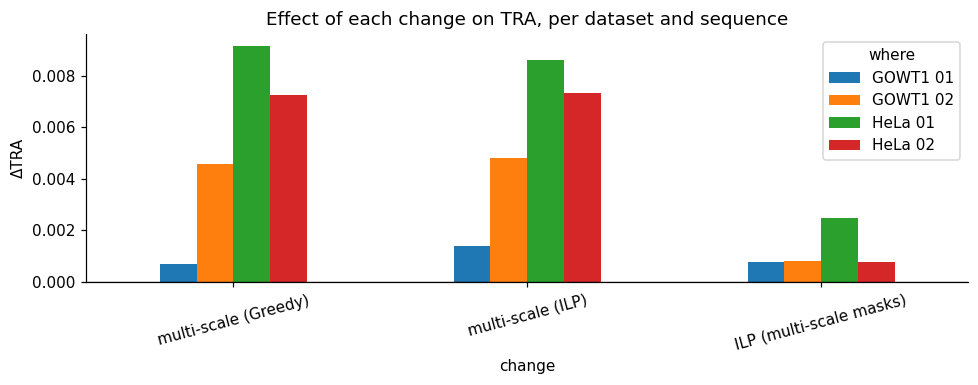

In [53]:
if len(hela):
    both = pd.concat([results.assign(dataset=DS.name), hela], ignore_index=True)
    pairs = {"multi-scale (Greedy)": ("B2-astra", "S1-astra"), "multi-scale (ILP)": ("B2-ilp", "S1-ilp"),
             "ILP (multi-scale masks)": ("S1-astra", "S1-ilp"), "fine-tuned (Greedy)": ("S1-astra", "S1-ft"),
             "fine-tuned (ILP)": ("S1-ilp", "S1-ft-ilp")}
    drows = []
    for label, (a, b) in pairs.items():
        for (dset, seq), g in both.groupby(["dataset", "seq"]):
            g = g.set_index("id")
            if a in g.index and b in g.index:
                drows.append({"change": label, "dataset": dset, "seq": seq,
                              **{f"Δ{m}": g.loc[b, m] - g.loc[a, m] for m in ["DET", "TRA", "CT", "BC(0)"]}})
    deltas = pd.DataFrame(drows)
    display(deltas.set_index(["change", "dataset", "seq"]).style.format("{:+.5f}")
            .background_gradient(cmap="RdBu", vmin=-0.02, vmax=0.02, subset=["ΔTRA", "ΔDET"])
            .set_caption("Table 10. Paired differences (B − A). Positive = the change helped."))

    fig, ax = plt.subplots(figsize=(9, 3.6))
    piv = deltas.assign(where=deltas.dataset.str.split("-").str[-1] + " " + deltas.seq) \
                .pivot(index="change", columns="where", values="ΔTRA")
    piv = piv.reindex([c for c in pairs if c in piv.index])
    piv.plot.bar(ax=ax, rot=15)
    ax.axhline(0, color="k", lw=0.8)
    ax.set(ylabel="ΔTRA", title="Effect of each change on TRA, per dataset and sequence")
    plt.tight_layout()
    plt.savefig(FIGS / "nb_cross_dataset_deltas.png", bbox_inches="tight")
    plt.show()

*Table 10 / Figure 10. Paired effects on GOWT1 and HeLa.* ZIHAO LI's runs found that multi-scale raised
TRA in all 8 HeLa pairs (+0.0077 to +0.0090), roughly twice the GOWT1 gain (+0.0042 to +0.0045). ILP
raised TRA but lowered CT, TF and BC(0), because it predicted more spurious divisions while finding
the same true ones. Fine-tuning on GOWT1 gave no consistent gain on HeLa. Check that your run agrees.

## 6. Discussion and error analysis

### 6.1 Who are the missed and spurious cells?
Each GT object is matched to a prediction at IoU ≥ 0.5 per frame (gold TRA markers as reference),
then FN and FP objects are characterised by brightness, size and distance to the border.

In [54]:
for seq in SEQS:
    res_dir = res_path(BEST, seq)
    if res_dir.exists():
        summarise(f"{BEST} / {seq}", analyse(DS / seq, res_dir, iou_threshold=0.0))


=== S1-ilp / 01 ===
frames 92   GT objects 2058   predicted 2186   matched 2038
FN 20 (1.0% of GT objects)   FP 148

FN object brightness (mean px intensity in the GT mask)
  detected GT objects: median 28.5   10th pct 6.4
  missed   GT objects: median 19.6   10th pct 3.7
  45% of FN are dimmer than the 25th-percentile detected cell (16)
  FN area    median 326 px   (GT objects that WERE detected: median 1658 px)
  FN touching border (<=8 px): 0%
  FN born same/previous frame: 35%

FP objects
  median area 1699 px   25th pct 1056   max 2741
  overlapping a GT object >30%: 0%  (these are fragments, not detections on empty background)
  touching border (<=8 px): 61%

matched-object area ratio res/GT: median 1.76x   p10 1.44   p90 2.22

=== S1-ilp / 02 ===
frames 92   GT objects 2517   predicted 2661   matched 2480
FN 73 (2.9% of GT objects)   FP 181

FN object brightness (mean px intensity in the GT mask)
  detected GT objects: median 10.2   10th pct 2.4
  missed   GT objects: median 7.

`iou_threshold=0.0` counts any overlap as a match, because TRA markers are smaller than full
masks (Table 3) and a strict threshold would count correct detections as errors.

### 6.2 Division events, one by one

In [55]:
def division_events(table: np.ndarray) -> pd.DataFrame:
    kids = table[table[:, 3] > 0]
    ev = pd.DataFrame(kids, columns=["L", "B", "E", "P"]).groupby("P").agg(frame=("B", "min"),
                                                                            daughters=("L", list))
    return ev.reset_index().rename(columns={"P": "mother"})


fig_rows = []
for seq in SEQS:
    imgs, tra, _, table = DATA[seq]
    ev = division_events(table)
    pred_tab = ctc_io.read_track_table(res_path(BEST, seq) / "res_track.txt")
    pred_dir = res_path(BEST, seq)
    first = min(imgs)
    for e in ev.itertuples():
        mom_mask = tra[e.frame - 1] == e.mother
        # did the prediction start two tracks with a common parent within ±1 frame near here?
        pm = ctc_io.read_mask(pred_dir / f"mask{e.frame - first:03d}.tif")
        near = np.unique(pm[ndimage.binary_dilation(mom_mask, iterations=10)])
        near = [int(v) for v in near if v > 0]
        parents = {int(r[3]) for r in pred_tab if int(r[0]) in near and r[3] > 0
                   and abs(int(r[1]) - (e.frame - first)) <= 1}
        row = dict(seq=seq, mother=e.mother, frame=e.frame, gt_daughters=e.daughters,
                   predicted_division=bool(parents))
        # were the daughters even segmented when they appear? (ZIHAO LI's division input check)
        births = {int(r[0]): int(r[1]) for r in table if int(r[0]) in e.daughters}
        for segname in ("cpsam", "multiscale"):
            d = seg_path(segname, seq)
            if not len(tif_files(d)):
                continue
            pm_all = ctc_io.list_masks(d)
            ok = 0
            for lab, b in births.items():
                marker = tra[b] == lab
                cand = ctc_io.read_mask(pm_all[b - first])[marker]
                cand = cand[cand > 0]
                ok += int(cand.size and np.bincount(cand).max() / marker.sum() > 0.5)
            row[f"daughters in {segname}"] = f"{ok}/{len(births)}"
        row["birth spread (frames)"] = max(births.values()) - min(births.values())
        fig_rows.append(row)
div_tab = pd.DataFrame(fig_rows)
div_tab

,seq,mother,frame,gt_daughters,predicted_division,daughters in cpsam,daughters in multiscale,birth spread (frames)
0,01,10,47,"[12, 14]",False,1/2,1/2,0
1,01,16,17,"[18, 22]",False,0/2,0/2,4
2,01,23,85,[35],False,0/1,0/1,0
3,02,2,36,[63],False,0/1,0/1,0
4,02,5,48,"[7, 8]",False,1/2,1/2,3
5,02,22,83,"[24, 25]",False,0/2,0/2,0
6,02,54,52,[4],False,1/1,1/1,0
7,02,58,17,[60],False,0/1,0/1,0
8,02,59,87,[66],False,1/1,1/1,0
9,02,60,25,"[61, 62]",False,0/2,0/2,0


*Table 8. Every gold division: did the best experiment produce one (two tracks with a common parent,
within ±1 frame, within 10 px of the mother)? Also, were the daughters segmented at all in the input
masks at their first GT frame (more than half of the GT marker covered by one predicted instance)?
`birth spread` > 0 means the GT itself has one daughter appear later than the other.* ZIHAO LI found
that every one of the 6 GOWT1 divisions has at least one daughter missing from the `cpsam` masks at
birth. A division the segmenter never sees cannot be linked, which is why BC(0) is 0 for every linker.
The lenient check here is not the official score; that is BC(0) in Table 5.

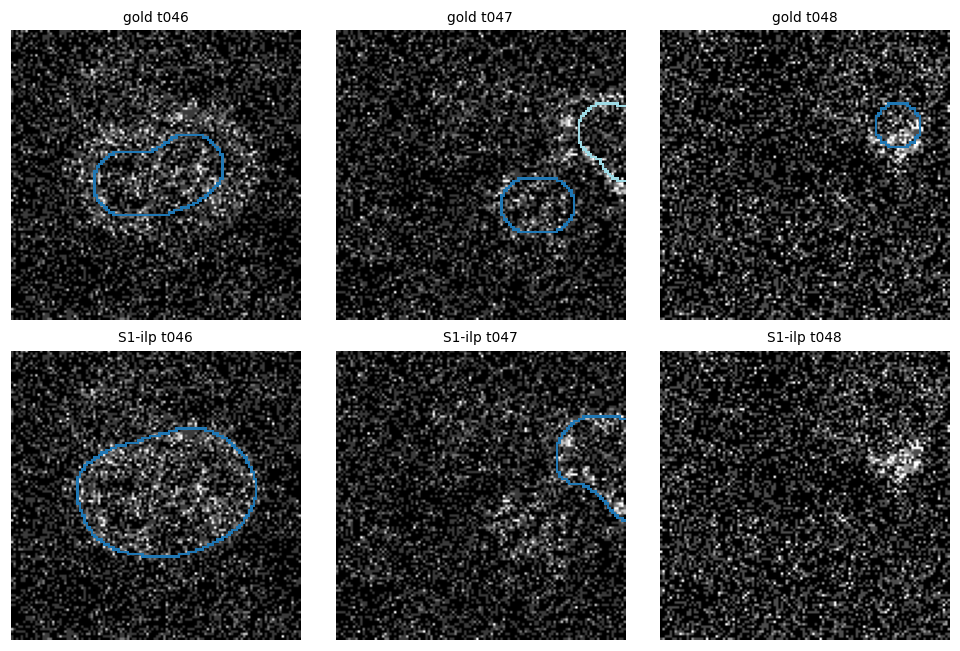

In [56]:
if len(div_tab):
    r0 = div_tab.iloc[0]
    imgs, tra, _, _ = DATA[r0.seq]
    pred_dir = res_path(BEST, r0.seq)
    first = min(imgs)
    cy, cx = ndimage.center_of_mass(tra[r0.frame - 1] == r0.mother)
    fig, axes = plt.subplots(2, 3, figsize=(9, 6))
    for j, f in enumerate([r0.frame - 1, r0.frame, min(r0.frame + 1, max(imgs))]):
        img = crop(imgs[f].astype(float), cy, cx, 60)
        show_overlay(axes[0, j], img, crop(tra[f], cy, cx, 60), f"gold t{f:03d}")
        show_overlay(axes[1, j], img, crop(ctc_io.read_mask(pred_dir / f"mask{f - first:03d}.tif"), cy, cx, 60),
                     f"{BEST} t{f:03d}")
    plt.tight_layout()
    plt.savefig(FIGS / "nb_division_case.png", bbox_inches="tight")
    plt.show()

*Figure 9. One division across three frames: gold (top) vs prediction (bottom). Outline colour
encodes track label, so a colour change in the bottom row at the split frame is a correct division.
The same colour continuing on one daughter means the mother track was continued (missing EC/EA).*

### 6.3 Discussion (_TODO, 2 marks_)
Answer from the tables above, with numbers:
1. **Segmentation vs linking.** How far is the best real row from B0 (oracle)? That gap is the
   segmentation error. How far is B0 from 1.0? That is the linker's own error.
2. **Which AOGM term dominates** for the best row (Fig. 6), and what does §6.1 say those objects are
   (dim? small? at the border?)?
3. **Recovering missed cells** (S1 vs B2, S1-astra vs B2-astra, S2-astra vs S1-astra). Multi-scale
   raised SEG on 01 but not on 02, and DET/TRA on both. How many of the added instances (§5.8) are real
   nuclei? Temporal recovery adds only a handful of instances and changes TRA by ~1e-4, so present it
   as an optional module, not part of the default pipeline (the conclusion of
   `plan/TEMPORAL_RECOVERY_RESULTS.md`). Parameters were tuned on 01, so 02 is the honest number.
4. **Rejected variants** (§4.2 table). CLAHE, morphology and cellprob tuning all failed. Why does
   adding whole cells beat refining boundaries for a recall-dominated metric?
5. **Border filter** (S0 vs B2). Does dropping edge-touching instances remove FPs (§6.1) without
   costing real cells that enter or leave the field of view?
6. **Divisions.** B2 vs B2-nodiv isolates the division rule. Does it help TRA, CT, BC(0)? Why does
   it fail on the events in Fig. 9? None of the segmentation changes target divisions.
7. **Linker engineering** (L-rows vs B2, Table 5b). The optimized linker gives identical accuracy and is
   2–3× faster; motion/hybrid ablations change at most one link. Turning divisions *off* is the only
   linker change that helps (02: 9 spurious divisions → 0). Table 8 explains why: in the masks, at least
   one daughter of every GOWT1 division is missing at birth, so no linker can recover it. The fix has to
   happen upstream (segmentation) or by linking late-appearing daughters.
8. **SOTA linker and decoder** (B2-astra, B2-ilp, S1-ilp). ILP gives the highest TRA, but Greedy gives
   higher CT, TF and BC(0). Which one you call "best" depends on the metric, so report both
   (S1-ilp as the headline, S1-astra for track completeness). Why does ILP's extra nodes help AOGM but
   its extra splits hurt BC?
9. **Fine-tuning** (S1-ft, S1-ft-ilp). It helped with GT markers (§4.3 table), but with Cellpose masks
   and on HeLa it gives no stable gain. Fine-tuning on 89 crops of one sequence can't fix errors that
   come from the detections.
10. **Generalisation** (§5.10). Multi-scale transfers to HeLa with a larger gain (denser, more missed
   nuclei to recover). Divisions are still the weak point: HeLa has hundreds of true divisions, so BC
   is measured properly there, unlike GOWT1's 4–6.
11. **Limitations.** GOWT1 02 was used both for picking the checkpoint and for reporting the
   Trackastra rows (ZIHAO LI's protocol), so HeLa is the only fully untouched test. Few GOWT1 division
   events (one event = a large swing in recall); GT SEG covers only some frames; TRA markers are smaller than SEG masks; GPU vs CPU runs can differ by a pixel and jitter
   the association, so fix the device for all rows.

## 7. Conclusion and future work
_TODO: 3–5 sentences. Main result (best row and its mean OP_CTB), what the error analysis says the
next fix should be, and one concrete future step._

## Appendix: environment

In [57]:
import importlib
for pkg in ["numpy", "scipy", "pandas", "tifffile", "matplotlib", "ctc_metrics", "cellpose", "torch", "trackastra"]:
    try:
        mod = importlib.import_module(pkg)
        print(f"{pkg:12s} {getattr(mod, '__version__', 'installed')}")
    except ImportError:
        print(f"{pkg:12s} not installed")
print("python      ", sys.version.split()[0])

numpy        2.4.6
scipy        1.16.3
pandas       2.2.3
tifffile     2026.10.15
matplotlib   3.10.0
ctc_metrics  installed
cellpose     installed
torch        2.14.1+cu130
trackastra   0.5.6
python       3.13.16
